In [2]:

# ============================================================
# PHASE 4: DELAY PROPAGATION & DOMINO EFFECT ANALYSIS
# CELL 1: LOAD AND VALIDATE PHASE 3 DATA
# ============================================================

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from IPython.display import display

# Project paths
project_path = os.path.abspath("..")
processed_path = os.path.join(
    project_path, "data", "processed"
)

input_file = os.path.join(
    processed_path,
    "aircraft_connections.csv"
)

if not os.path.exists(input_file):
    raise FileNotFoundError(
        "Phase 3 aircraft_connections.csv was not found."
    )

# Load validated aircraft connections
connections = pd.read_csv(
    input_file,
    low_memory=False
)

print("=" * 65)
print("PHASE 4: DELAY PROPAGATION ANALYSIS")
print("=" * 65)

print("\nDATASET INFORMATION")
print("-------------------")
print("Dataset shape:", connections.shape)
print("Total validated connections:", len(connections))

# Required columns
required_columns = [
    "PREV_FLIGHT_ID",
    "NEXT_FLIGHT_ID",
    "PREV_TAIL_NUM",
    "PREV_ARR_DELAY",
    "NEXT_DEP_DELAY",
    "ACTUAL_TURNAROUND_MIN",
    "SCHEDULED_TURNAROUND_BUFFER_MIN",
    "BUFFER_CONSUMED_MIN"
]

missing_columns = [
    col for col in required_columns
    if col not in connections.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("\nAll required columns are available.")

# Check whether Phase 3 saved only valid connections
if "CONNECTION_VALID" in connections.columns:
    print(
        "\nConnection validity:",
        connections["CONNECTION_VALID"].value_counts(
            dropna=False
        ).to_dict()
    )

# Check duplicate connection pairs
duplicate_count = connections.duplicated(
    subset=["PREV_FLIGHT_ID", "NEXT_FLIGHT_ID"]
).sum()

print("Duplicate connection pairs:", duplicate_count)

print("\nSample records:")
display(connections.head())


PHASE 4: DELAY PROPAGATION ANALYSIS

DATASET INFORMATION
-------------------
Dataset shape: (479665, 35)
Total validated connections: 479665

All required columns are available.

Connection validity: {True: 479665}
Duplicate connection pairs: 0

Sample records:


,PREV_FLIGHT_ID,PREV_TAIL_NUM,PREV_CARRIER,PREV_FLIGHT_NUM,PREV_FL_DATE,PREV_ORIGIN,PREV_DEST,PREV_DEP_UTC,PREV_ARR_UTC,PREV_CRS_DEP_UTC,...,NEXT_ARR_DELAY,SAME_AIRCRAFT,AIRPORT_CONTINUITY,ACTUAL_TIME_VALID,ACTUAL_TURNAROUND_MIN,SCHEDULED_TURNAROUND_BUFFER_MIN,BUFFER_CONSUMED_MIN,SHORT_TURNAROUND_FLAG,CONNECTION_VALID,CONNECTION_REJECTION_REASON
0,FL0,188NV,G4,1397,2026-01-01,TYS,BOS,2026-01-01 14:34:00+00:00,2026-01-01 16:58:00+00:00,2026-01-01 14:45:00+00:00,...,-9.0,True,True,True,42.0,50.0,8.0,False,True,VALID
1,FL1,188NV,G4,1398,2026-01-01,BOS,TYS,2026-01-01 17:40:00+00:00,2026-01-01 20:07:00+00:00,2026-01-01 17:45:00+00:00,...,-5.0,True,True,True,959.0,959.0,0.0,False,True,VALID
2,FL2,188NV,G4,1396,2026-01-02,TYS,EWR,2026-01-02 12:06:00+00:00,2026-01-02 14:00:00+00:00,2026-01-02 12:15:00+00:00,...,-7.0,True,True,True,47.0,50.0,3.0,False,True,VALID
3,FL3,188NV,G4,1399,2026-01-02,EWR,TYS,2026-01-02 14:47:00+00:00,2026-01-02 16:48:00+00:00,2026-01-02 14:55:00+00:00,...,-5.0,True,True,True,51.0,50.0,-1.0,False,True,VALID
4,FL4,188NV,G4,3030,2026-01-02,TYS,PIE,2026-01-02 17:39:00+00:00,2026-01-02 19:22:00+00:00,2026-01-02 17:45:00+00:00,...,-3.0,True,True,True,44.0,50.0,6.0,False,True,VALID


In [3]:

# ============================================================
# CELL 2: DATA PREPARATION
# ============================================================

numeric_columns = [
    "PREV_ARR_DELAY",
    "NEXT_DEP_DELAY",
    "ACTUAL_TURNAROUND_MIN",
    "SCHEDULED_TURNAROUND_BUFFER_MIN",
    "BUFFER_CONSUMED_MIN"
]

# Convert analysis columns to numeric
for col in numeric_columns:
    connections[col] = pd.to_numeric(
        connections[col],
        errors="coerce"
    )

original_count = len(connections)

# Check missing values before filtering
print("MISSING VALUES BEFORE CLEANING")
print("--------------------------------")
display(
    connections[numeric_columns]
    .isna()
    .sum()
    .to_frame("Missing_Count")
)

# Core delay propagation requires:
# Previous arrival delay, next departure delay,
# and a valid positive actual turnaround.

analysis_data = connections.dropna(
    subset=[
        "PREV_ARR_DELAY",
        "NEXT_DEP_DELAY",
        "ACTUAL_TURNAROUND_MIN"
    ]
).copy()

analysis_data = analysis_data[
    analysis_data["ACTUAL_TURNAROUND_MIN"] > 0
].copy()

# Remove duplicate pairs if any remain
analysis_data = analysis_data.drop_duplicates(
    subset=["PREV_FLIGHT_ID", "NEXT_FLIGHT_ID"]
).copy()

print("\nDATA PREPARATION REPORT")
print("-----------------------")
print("Original connections:", original_count)
print("Usable connections:", len(analysis_data))
print("Removed connections:", original_count - len(analysis_data))

print(
    "\nMissing scheduled buffer values:",
    analysis_data["SCHEDULED_TURNAROUND_BUFFER_MIN"].isna().sum()
)

print(
    "Missing buffer consumed values:",
    analysis_data["BUFFER_CONSUMED_MIN"].isna().sum()
)

print(
    "\nFinal analysis dataset shape:",
    analysis_data.shape
)

display(analysis_data.head())


MISSING VALUES BEFORE CLEANING
--------------------------------


,Missing_Count
PREV_ARR_DELAY,0
NEXT_DEP_DELAY,0
ACTUAL_TURNAROUND_MIN,0
SCHEDULED_TURNAROUND_BUFFER_MIN,0
BUFFER_CONSUMED_MIN,0



DATA PREPARATION REPORT
-----------------------
Original connections: 479665
Usable connections: 479665
Removed connections: 0

Missing scheduled buffer values: 0
Missing buffer consumed values: 0

Final analysis dataset shape: (479665, 35)


,PREV_FLIGHT_ID,PREV_TAIL_NUM,PREV_CARRIER,PREV_FLIGHT_NUM,PREV_FL_DATE,PREV_ORIGIN,PREV_DEST,PREV_DEP_UTC,PREV_ARR_UTC,PREV_CRS_DEP_UTC,...,NEXT_ARR_DELAY,SAME_AIRCRAFT,AIRPORT_CONTINUITY,ACTUAL_TIME_VALID,ACTUAL_TURNAROUND_MIN,SCHEDULED_TURNAROUND_BUFFER_MIN,BUFFER_CONSUMED_MIN,SHORT_TURNAROUND_FLAG,CONNECTION_VALID,CONNECTION_REJECTION_REASON
0,FL0,188NV,G4,1397,2026-01-01,TYS,BOS,2026-01-01 14:34:00+00:00,2026-01-01 16:58:00+00:00,2026-01-01 14:45:00+00:00,...,-9.0,True,True,True,42.0,50.0,8.0,False,True,VALID
1,FL1,188NV,G4,1398,2026-01-01,BOS,TYS,2026-01-01 17:40:00+00:00,2026-01-01 20:07:00+00:00,2026-01-01 17:45:00+00:00,...,-5.0,True,True,True,959.0,959.0,0.0,False,True,VALID
2,FL2,188NV,G4,1396,2026-01-02,TYS,EWR,2026-01-02 12:06:00+00:00,2026-01-02 14:00:00+00:00,2026-01-02 12:15:00+00:00,...,-7.0,True,True,True,47.0,50.0,3.0,False,True,VALID
3,FL3,188NV,G4,1399,2026-01-02,EWR,TYS,2026-01-02 14:47:00+00:00,2026-01-02 16:48:00+00:00,2026-01-02 14:55:00+00:00,...,-5.0,True,True,True,51.0,50.0,-1.0,False,True,VALID
4,FL4,188NV,G4,3030,2026-01-02,TYS,PIE,2026-01-02 17:39:00+00:00,2026-01-02 19:22:00+00:00,2026-01-02 17:45:00+00:00,...,-3.0,True,True,True,44.0,50.0,6.0,False,True,VALID


In [4]:
# ============================================================
# CELL 3: IDENTIFY POTENTIAL DELAY PROPAGATION
# ============================================================

DELAY_THRESHOLD = 15

# Classify previous flight arrival delays
analysis_data["PREVIOUS_DELAYED"] = (
    analysis_data["PREV_ARR_DELAY"] >= DELAY_THRESHOLD
)

# Classify next flight departure delays
analysis_data["NEXT_DELAYED"] = (
    analysis_data["NEXT_DEP_DELAY"] >= DELAY_THRESHOLD
)

# Identify potential propagation events
analysis_data["POTENTIAL_PROPAGATION"] = (
    analysis_data["PREVIOUS_DELAYED"] &
    analysis_data["NEXT_DELAYED"]
)

# Calculate counts
total_connections = len(analysis_data)

previous_delayed = analysis_data[
    analysis_data["PREVIOUS_DELAYED"]
]

previous_not_delayed = analysis_data[
    ~analysis_data["PREVIOUS_DELAYED"]
]

propagation_events = analysis_data[
    analysis_data["POTENTIAL_PROPAGATION"]
]

print("=" * 65)
print("DELAY PROPAGATION ANALYSIS")
print("=" * 65)

print("\nTOTAL CONNECTIONS:", total_connections)

print(
    "\nConnections where previous flight was delayed:",
    len(previous_delayed)
)

print(
    "Connections where previous flight was not delayed:",
    len(previous_not_delayed)
)

print(
    "\nPotential propagation events:",
    len(propagation_events)
)

# Conditional propagation rates
rate_after_delay = (
    previous_delayed["NEXT_DELAYED"].mean() * 100
)

rate_without_delay = (
    previous_not_delayed["NEXT_DELAYED"].mean() * 100
)

print("\nNEXT FLIGHT DELAY RATE")
print("----------------------")

print(
    f"After a delayed previous flight: "
    f"{rate_after_delay:.2f}%"
)

print(
    f"After a non-delayed previous flight: "
    f"{rate_without_delay:.2f}%"
)

print(
    "\nDifference in delay rates:",
    f"{rate_after_delay - rate_without_delay:.2f} percentage points"
)

print("\nPOTENTIAL PROPAGATION RATE:")

print(
    f"{len(propagation_events) / total_connections * 100:.2f}% "
    "of all connections"
)

DELAY PROPAGATION ANALYSIS

TOTAL CONNECTIONS: 479665

Connections where previous flight was delayed: 95879
Connections where previous flight was not delayed: 383786

Potential propagation events: 52013

NEXT FLIGHT DELAY RATE
----------------------
After a delayed previous flight: 54.25%
After a non-delayed previous flight: 9.81%

Difference in delay rates: 44.44 percentage points

POTENTIAL PROPAGATION RATE:
10.84% of all connections


In [5]:
# ============================================================
# CELL 4: PREVIOUS FLIGHT DELAY CATEGORIES
# ============================================================

# Categorize previous flight arrival delays
bins = [-np.inf, 0, 15, 30, 60, 120, np.inf]

labels = [
    "Early",
    "0-14 min",
    "15-29 min",
    "30-59 min",
    "60-119 min",
    "120+ min"
]

analysis_data["PREVIOUS_DELAY_CATEGORY"] = pd.cut(
    analysis_data["PREV_ARR_DELAY"],
    bins=bins,
    labels=labels,
    right=False
)

# Analyze next flight delays for each category
category_analysis = (
    analysis_data
    .groupby("PREVIOUS_DELAY_CATEGORY", observed=False)
    .agg(
        CONNECTIONS=("NEXT_DEP_DELAY", "count"),
        AVG_NEXT_DEP_DELAY=("NEXT_DEP_DELAY", "mean"),
        MEDIAN_NEXT_DEP_DELAY=("NEXT_DEP_DELAY", "median"),
        NEXT_DELAYED_COUNT=("NEXT_DELAYED", "sum"),
        NEXT_DELAY_RATE=("NEXT_DELAYED", "mean")
    )
    .reset_index()
)

category_analysis["NEXT_DELAY_RATE"] *= 100

print("DELAY CATEGORY ANALYSIS")
print("=" * 65)

display(category_analysis.round(2))

DELAY CATEGORY ANALYSIS


,PREVIOUS_DELAY_CATEGORY,CONNECTIONS,AVG_NEXT_DEP_DELAY,MEDIAN_NEXT_DEP_DELAY,NEXT_DELAYED_COUNT,NEXT_DELAY_RATE
0,Early,307790,0.41,-4.0,24770,8.05
1,0-14 min,75996,6.65,0.0,12868,16.93
2,15-29 min,33840,15.26,9.0,13543,40.02
3,30-59 min,29037,27.30,25.0,17457,60.12
4,60-119 min,20125,49.14,51.0,12883,64.01
5,120+ min,12877,93.54,76.0,8130,63.14


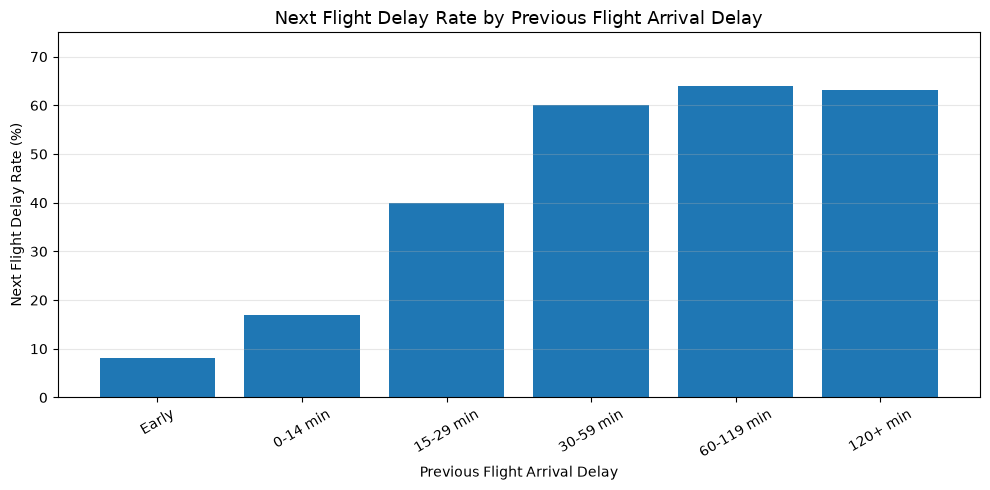

In [6]:
# ============================================================
# CELL 5: VISUALIZE DELAY PROPAGATION BY CATEGORY
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    category_analysis["PREVIOUS_DELAY_CATEGORY"].astype(str),
    category_analysis["NEXT_DELAY_RATE"]
)

plt.title(
    "Next Flight Delay Rate by Previous Flight Arrival Delay",
    fontsize=13
)

plt.xlabel("Previous Flight Arrival Delay")
plt.ylabel("Next Flight Delay Rate (%)")

plt.ylim(0, 75)
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# CELL 6: TURNAROUND BUFFER CONSUMPTION ANALYSIS
# ============================================================

# Categorize the amount of turnaround buffer consumed
buffer_bins = [-np.inf, 0, 15, 30, 60, 120, np.inf]

buffer_labels = [
    "Buffer gained",
    "0-14 min",
    "15-29 min",
    "30-59 min",
    "60-119 min",
    "120+ min"
]

analysis_data["BUFFER_CONSUMPTION_CATEGORY"] = pd.cut(
    analysis_data["BUFFER_CONSUMED_MIN"],
    bins=buffer_bins,
    labels=buffer_labels,
    right=False
)

# Analyze delay behavior for each buffer category
buffer_analysis = (
    analysis_data
    .groupby(
        "BUFFER_CONSUMPTION_CATEGORY",
        observed=False
    )
    .agg(
        CONNECTIONS=("NEXT_DEP_DELAY", "count"),
        AVG_PREVIOUS_ARR_DELAY=("PREV_ARR_DELAY", "mean"),
        AVG_NEXT_DEP_DELAY=("NEXT_DEP_DELAY", "mean"),
        NEXT_DELAYED_COUNT=("NEXT_DELAYED", "sum"),
        NEXT_DELAY_RATE=("NEXT_DELAYED", "mean")
    )
    .reset_index()
)

buffer_analysis["NEXT_DELAY_RATE"] *= 100

print("=" * 65)
print("TURNAROUND BUFFER CONSUMPTION ANALYSIS")
print("=" * 65)

display(buffer_analysis.round(2))

TURNAROUND BUFFER CONSUMPTION ANALYSIS


,BUFFER_CONSUMPTION_CATEGORY,CONNECTIONS,AVG_PREVIOUS_ARR_DELAY,AVG_NEXT_DEP_DELAY,NEXT_DELAYED_COUNT,NEXT_DELAY_RATE
0,Buffer gained,312780,-11.09,8.91,58849,18.81
1,0-14 min,107227,12.01,6.47,18757,17.49
2,15-29 min,28234,30.52,10.23,5982,21.19
3,30-59 min,15394,50.05,8.53,2779,18.05
4,60-119 min,9485,91.18,8.75,1677,17.68
5,120+ min,6545,226.10,22.63,1607,24.55


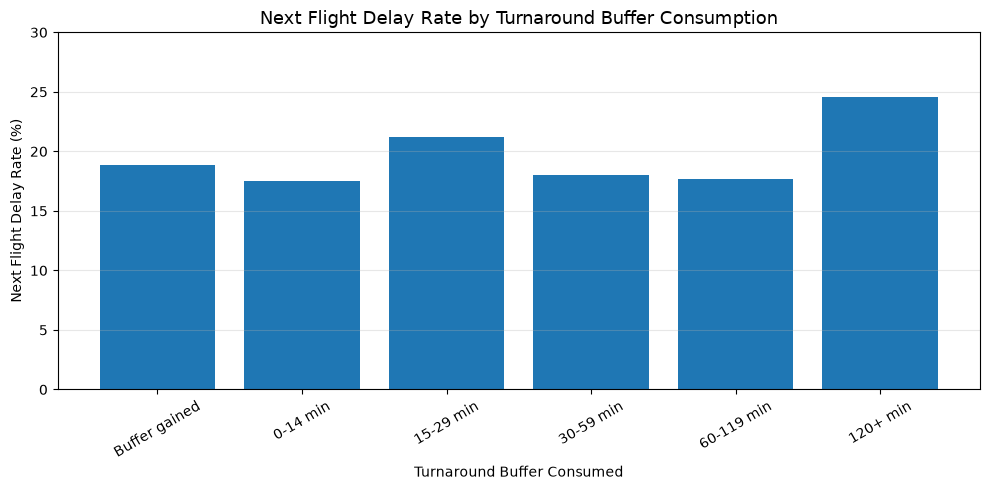

In [8]:
# ============================================================
# CELL 7: VISUALIZE TURNAROUND BUFFER CONSUMPTION
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    buffer_analysis["BUFFER_CONSUMPTION_CATEGORY"].astype(str),
    buffer_analysis["NEXT_DELAY_RATE"]
)

plt.title(
    "Next Flight Delay Rate by Turnaround Buffer Consumption",
    fontsize=13
)

plt.xlabel("Turnaround Buffer Consumed")
plt.ylabel("Next Flight Delay Rate (%)")

plt.ylim(0, 30)
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# CELL 8: ARRIVAL DELAY VS BUFFER CONSUMPTION
# ============================================================

# Calculate correlation
correlation = analysis_data[
    ["PREV_ARR_DELAY", "BUFFER_CONSUMED_MIN"]
].corr().iloc[0, 1]

print("=" * 65)
print("ARRIVAL DELAY VS BUFFER CONSUMPTION")
print("=" * 65)

print(
    f"\nCorrelation coefficient: {correlation:.4f}"
)

# Group previous arrival delays into categories
delay_buffer_analysis = (
    analysis_data
    .groupby(
        "PREVIOUS_DELAY_CATEGORY",
        observed=False
    )
    .agg(
        CONNECTIONS=("BUFFER_CONSUMED_MIN", "count"),
        AVG_BUFFER_CONSUMED=("BUFFER_CONSUMED_MIN", "mean"),
        MEDIAN_BUFFER_CONSUMED=("BUFFER_CONSUMED_MIN", "median")
    )
    .reset_index()
)

print("\nBUFFER CONSUMPTION BY PREVIOUS ARRIVAL DELAY")
print("-" * 65)

display(delay_buffer_analysis.round(2))

ARRIVAL DELAY VS BUFFER CONSUMPTION

Correlation coefficient: 0.6261

BUFFER CONSUMPTION BY PREVIOUS ARRIVAL DELAY
-----------------------------------------------------------------


,PREVIOUS_DELAY_CATEGORY,CONNECTIONS,AVG_BUFFER_CONSUMED,MEDIAN_BUFFER_CONSUMED
0,Early,307790,-16.02,-12.0
1,0-14 min,75996,-0.34,5.0
2,15-29 min,33840,6.39,11.0
3,30-59 min,29037,15.68,15.0
4,60-119 min,20125,34.93,25.0
5,120+ min,12877,113.83,108.0


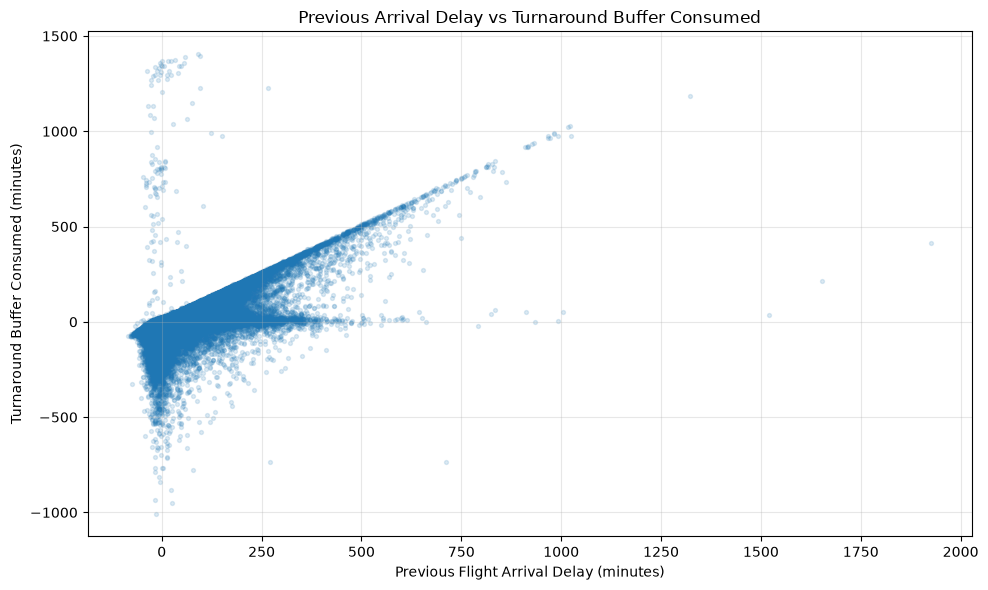

In [10]:
# ============================================================
# CELL 9: ARRIVAL DELAY VS BUFFER CONSUMPTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    analysis_data["PREV_ARR_DELAY"],
    analysis_data["BUFFER_CONSUMED_MIN"],
    alpha=0.15,
    s=8
)

plt.title(
    "Previous Arrival Delay vs Turnaround Buffer Consumed"
)

plt.xlabel("Previous Flight Arrival Delay (minutes)")
plt.ylabel("Turnaround Buffer Consumed (minutes)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# CELL 9: VALIDATE BUFFER CONSUMPTION FORMULA
# ============================================================

analysis_data["CALCULATED_BUFFER_CONSUMED"] = (
    analysis_data["PREV_ARR_DELAY"] -
    analysis_data["NEXT_DEP_DELAY"]
)

analysis_data["BUFFER_DIFFERENCE"] = (
    analysis_data["BUFFER_CONSUMED_MIN"] -
    analysis_data["CALCULATED_BUFFER_CONSUMED"]
)

print("BUFFER FORMULA VALIDATION")
print("=" * 60)

print(
    "Maximum absolute difference:",
    analysis_data["BUFFER_DIFFERENCE"].abs().max()
)

print(
    "Mean absolute difference:",
    analysis_data["BUFFER_DIFFERENCE"].abs().mean()
)

print(
    "Records with difference above 1 minute:",
    (analysis_data["BUFFER_DIFFERENCE"].abs() > 1).sum()
)

BUFFER FORMULA VALIDATION
Maximum absolute difference: 2880.0
Mean absolute difference: 0.48338319452117623
Records with difference above 1 minute: 163


In [12]:
# ============================================================
# CELL 10: AIRLINE-WISE PROPAGATION ANALYSIS
# ============================================================

airline_analysis = (
    analysis_data
    .groupby("PREV_CARRIER")
    .agg(
        CONNECTIONS=("NEXT_DEP_DELAY", "count"),
        PREVIOUS_DELAYED_COUNT=("PREVIOUS_DELAYED", "sum"),
        PROPAGATION_EVENTS=("POTENTIAL_PROPAGATION", "sum"),
        NEXT_DELAY_RATE=("NEXT_DELAYED", "mean")
    )
    .reset_index()
)

airline_analysis["NEXT_DELAY_RATE"] *= 100

airline_analysis["PROPAGATION_RATE"] = (
    airline_analysis["PROPAGATION_EVENTS"] /
    airline_analysis["PREVIOUS_DELAYED_COUNT"].replace(0, np.nan)
) * 100

# Avoid drawing conclusions from very small samples
airline_analysis = airline_analysis[
    airline_analysis["CONNECTIONS"] >= 500
].copy()

airline_analysis = airline_analysis.sort_values(
    "PROPAGATION_RATE",
    ascending=False
)

print("AIRLINE-WISE PROPAGATION ANALYSIS")
print("=" * 65)

display(airline_analysis.round(2))

AIRLINE-WISE PROPAGATION ANALYSIS


,PREV_CARRIER,CONNECTIONS,PREVIOUS_DELAYED_COUNT,PROPAGATION_EVENTS,NEXT_DELAY_RATE,PROPAGATION_RATE
5,G4,7753,1797,1211,23.26,67.39
8,OH,16055,3642,2313,20.72,63.51
7,NK,10318,2778,1758,28.55,63.28
4,F9,13254,3443,2150,24.50,62.45
2,B6,14799,4565,2639,26.76,57.81
9,OO,59828,13335,7708,18.39,57.80
11,WN,97735,14704,8481,17.24,57.68
1,AS,22683,4634,2621,20.51,56.56
12,YX,25644,5056,2721,15.80,53.82
6,MQ,21869,4337,2291,16.84,52.82


In [13]:
# ============================================================
# CELL 11: ACTUAL TURNAROUND TIME ANALYSIS
# ============================================================

turnaround_bins = [
    0, 30, 60, 90, 120, 180, np.inf
]

turnaround_labels = [
    "0-29 min",
    "30-59 min",
    "60-89 min",
    "90-119 min",
    "120-179 min",
    "180+ min"
]

analysis_data["TURNAROUND_CATEGORY"] = pd.cut(
    analysis_data["ACTUAL_TURNAROUND_MIN"],
    bins=turnaround_bins,
    labels=turnaround_labels,
    right=False
)

turnaround_analysis = (
    analysis_data
    .groupby("TURNAROUND_CATEGORY", observed=False)
    .agg(
        CONNECTIONS=("NEXT_DEP_DELAY", "count"),
        AVG_NEXT_DEP_DELAY=("NEXT_DEP_DELAY", "mean"),
        NEXT_DELAYED_COUNT=("NEXT_DELAYED", "sum"),
        NEXT_DELAY_RATE=("NEXT_DELAYED", "mean")
    )
    .reset_index()
)

turnaround_analysis["NEXT_DELAY_RATE"] *= 100

print("TURNAROUND TIME ANALYSIS")
print("=" * 65)

display(turnaround_analysis.round(2))

TURNAROUND TIME ANALYSIS


,TURNAROUND_CATEGORY,CONNECTIONS,AVG_NEXT_DEP_DELAY,NEXT_DELAYED_COUNT,NEXT_DELAY_RATE
0,0-29 min,9324,32.04,3904,41.87
1,30-59 min,144877,9.19,31826,21.97
2,60-89 min,130097,4.54,20014,15.38
3,90-119 min,42838,7.90,8793,20.53
4,120-179 min,21885,20.15,7089,32.39
5,180+ min,130644,8.68,18025,13.80


In [14]:
# ============================================================
# CELL 12: ESTIMATED REMAINING BUFFER ANALYSIS
# ============================================================

# Estimate how much scheduled turnaround time remains
# after accounting for the previous flight's arrival delay.

analysis_data["ESTIMATED_REMAINING_BUFFER_MIN"] = (
    analysis_data["SCHEDULED_TURNAROUND_BUFFER_MIN"] -
    analysis_data["PREV_ARR_DELAY"]
)

remaining_buffer_bins = [
    -np.inf, -30, 0, 15, 30, 60, np.inf
]

remaining_buffer_labels = [
    "Shortfall >30 min",
    "Shortfall 0-29 min",
    "0-14 min remaining",
    "15-29 min remaining",
    "30-59 min remaining",
    "60+ min remaining"
]

analysis_data["REMAINING_BUFFER_CATEGORY"] = pd.cut(
    analysis_data["ESTIMATED_REMAINING_BUFFER_MIN"],
    bins=remaining_buffer_bins,
    labels=remaining_buffer_labels,
    right=False
)

remaining_buffer_analysis = (
    analysis_data
    .groupby("REMAINING_BUFFER_CATEGORY", observed=False)
    .agg(
        CONNECTIONS=("NEXT_DEP_DELAY", "count"),
        AVG_NEXT_DEP_DELAY=("NEXT_DEP_DELAY", "mean"),
        NEXT_DELAYED_COUNT=("NEXT_DELAYED", "sum"),
        NEXT_DELAY_RATE=("NEXT_DELAYED", "mean")
    )
    .reset_index()
)

remaining_buffer_analysis["NEXT_DELAY_RATE"] *= 100

print("ESTIMATED REMAINING BUFFER ANALYSIS")
print("=" * 65)

display(remaining_buffer_analysis.round(2))

ESTIMATED REMAINING BUFFER ANALYSIS


,REMAINING_BUFFER_CATEGORY,CONNECTIONS,AVG_NEXT_DEP_DELAY,NEXT_DELAYED_COUNT,NEXT_DELAY_RATE
0,Shortfall >30 min,10491,141.80,10489,99.98
1,Shortfall 0-29 min,9310,63.24,9310,100.00
2,0-14 min remaining,9351,42.43,9035,96.62
3,15-29 min remaining,18394,25.23,12087,65.71
4,30-59 min remaining,112632,4.73,18858,16.74
5,60+ min remaining,319487,2.08,29872,9.35


HIGH-RISK CONNECTION ANALYSIS


,RISK_GROUP,CONNECTIONS,AVG_NEXT_DEP_DELAY,NEXT_DELAYED_COUNT,NEXT_DELAY_RATE
0,Delayed incoming + low buffer,29460,84.06,29031,98.54
1,Delayed incoming + sufficient buffer,66419,15.45,22982,34.60
2,On-time incoming + low buffer,564,48.51,559,99.11
3,On-time incoming + sufficient buffer,383222,1.57,37079,9.68


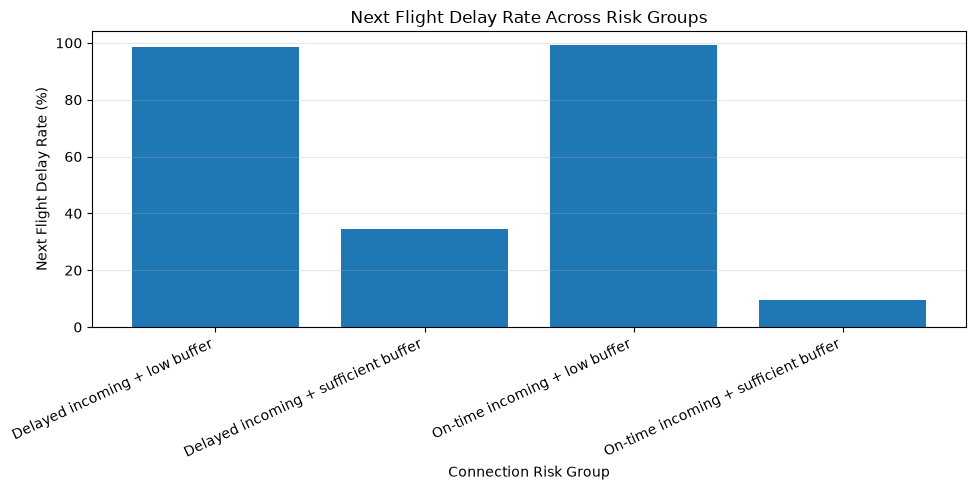

In [15]:
# ============================================================
# CELL 13: HIGH-RISK CONNECTION IDENTIFICATION
# ============================================================

conditions = [
    (
        analysis_data["PREVIOUS_DELAYED"] &
        (analysis_data["ESTIMATED_REMAINING_BUFFER_MIN"] <= 15)
    ),
    (
        analysis_data["PREVIOUS_DELAYED"] &
        (analysis_data["ESTIMATED_REMAINING_BUFFER_MIN"] > 15)
    ),
    (
        ~analysis_data["PREVIOUS_DELAYED"] &
        (analysis_data["ESTIMATED_REMAINING_BUFFER_MIN"] <= 15)
    )
]

risk_labels = [
    "Delayed incoming + low buffer",
    "Delayed incoming + sufficient buffer",
    "On-time incoming + low buffer"
]

analysis_data["RISK_GROUP"] = np.select(
    conditions,
    risk_labels,
    default="On-time incoming + sufficient buffer"
)

risk_analysis = (
    analysis_data
    .groupby("RISK_GROUP")
    .agg(
        CONNECTIONS=("NEXT_DEP_DELAY", "count"),
        AVG_NEXT_DEP_DELAY=("NEXT_DEP_DELAY", "mean"),
        NEXT_DELAYED_COUNT=("NEXT_DELAYED", "sum"),
        NEXT_DELAY_RATE=("NEXT_DELAYED", "mean")
    )
    .reset_index()
)

risk_analysis["NEXT_DELAY_RATE"] *= 100

print("HIGH-RISK CONNECTION ANALYSIS")
print("=" * 65)

display(risk_analysis.round(2))

# Visualize risk groups
plt.figure(figsize=(10, 5))

plt.bar(
    risk_analysis["RISK_GROUP"],
    risk_analysis["NEXT_DELAY_RATE"]
)

plt.title("Next Flight Delay Rate Across Risk Groups")
plt.xlabel("Connection Risk Group")
plt.ylabel("Next Flight Delay Rate (%)")

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# CELL 14: CORRELATION ANALYSIS
# ============================================================

from scipy.stats import pearsonr, spearmanr

x = analysis_data["PREV_ARR_DELAY"]
y = analysis_data["NEXT_DEP_DELAY"]

pearson_corr, pearson_p = pearsonr(x, y)
spearman_corr, spearman_p = spearmanr(x, y)

print("DELAY PROPAGATION CORRELATION")
print("=" * 65)

print(f"Pearson correlation:  {pearson_corr:.4f}")
print(f"Pearson p-value:      {pearson_p:.6g}")

print(f"\nSpearman correlation: {spearman_corr:.4f}")
print(f"Spearman p-value:     {spearman_p:.6g}")

DELAY PROPAGATION CORRELATION
Pearson correlation:  0.4254
Pearson p-value:      0

Spearman correlation: 0.3998
Spearman p-value:     0


In [17]:
# ============================================================
# CELL 15: EXPLORATORY MULTIPLE LINEAR REGRESSION
# ============================================================

# Use a reproducible sample to make computation manageable
regression_data = analysis_data.sample(
    n=min(100000, len(analysis_data)),
    random_state=42
).copy()

# Prepare predictors
X = pd.get_dummies(
    regression_data[
        [
            "PREV_ARR_DELAY",
            "SCHEDULED_TURNAROUND_BUFFER_MIN",
            "PREV_CARRIER"
        ]
    ],
    columns=["PREV_CARRIER"],
    drop_first=True,
    dtype=float
)

y = regression_data["NEXT_DEP_DELAY"].to_numpy(dtype=float)

# Add intercept
X_matrix = np.column_stack([
    np.ones(len(X)),
    X.to_numpy(dtype=float)
])

# Fit regression using least squares
coefficients, residuals, rank, singular_values = np.linalg.lstsq(
    X_matrix,
    y,
    rcond=None
)

predictions = X_matrix @ coefficients

# Calculate R-squared
ss_total = np.sum((y - y.mean()) ** 2)
ss_residual = np.sum((y - predictions) ** 2)

r_squared = 1 - (ss_residual / ss_total)

# Display important coefficients
coefficient_names = ["Intercept"] + list(X.columns)

regression_results = pd.DataFrame({
    "Variable": coefficient_names,
    "Coefficient": coefficients
})

print("EXPLORATORY REGRESSION RESULTS")
print("=" * 65)

print("Sample size:", len(regression_data))
print(f"R-squared: {r_squared:.4f}")

print("\nMain predictor coefficients:")

display(
    regression_results[
        regression_results["Variable"].isin([
            "Intercept",
            "PREV_ARR_DELAY",
            "SCHEDULED_TURNAROUND_BUFFER_MIN"
        ])
    ].round(4)
)

EXPLORATORY REGRESSION RESULTS
Sample size: 100000
R-squared: 0.1902

Main predictor coefficients:


,Variable,Coefficient
0,Intercept,13.7080
1,PREV_ARR_DELAY,0.3854
2,SCHEDULED_TURNAROUND_BUFFER_MIN,-0.0137


In [ ]:
# ============================================================
# CELL 16: PHASE 4 FINAL SUMMARY
# ============================================================

print("=" * 70)
print("PHASE 4: FINAL DELAY PROPAGATION SUMMARY")
print("=" * 70)

print("\nDATASET")
print("Total connections:", len(analysis_data))

print("\nDELAY PROPAGATION")
print(
    "Previous flight delayed:",
    analysis_data["PREVIOUS_DELAYED"].sum()
)

print(
    "Potential propagation events:",
    analysis_data["POTENTIAL_PROPAGATION"].sum()
)

print(
    "Next-flight delay rate after delayed arrival:",
    f"{rate_after_delay:.2f}%"
)

print(
    "Next-flight delay rate after non-delayed arrival:",
    f"{rate_without_delay:.2f}%"
)

print("\nBUFFER ANALYSIS")
print(
    "Arrival delay vs buffer consumption correlation:",
    f"{correlation:.4f}"
)

print(
    "Previous arrival vs next departure Pearson correlation:",
    f"{pearson_corr:.4f}"
)

print("\nRISK ANALYSIS")
print(
    "High-risk connections:",
    (
        analysis_data["RISK_GROUP"] ==
        "Delayed incoming + low buffer"
    ).sum()
)

print("\nREGRESSION")
print(f"R-squared: {r_squared:.4f}")


# ------------------------------------------------------------
# SAVE PHASE 4 OUTPUTS
# ------------------------------------------------------------

os.makedirs(processed_path, exist_ok=True)

# Save the complete prepared analysis dataset
analysis_data.to_csv(
    os.path.join(processed_path, "phase4_analysis_data.csv"),
    index=False
)

# Save analysis tables
output_tables = {
    "phase4_delay_category_analysis.csv": category_analysis,
    "phase4_buffer_analysis.csv": buffer_analysis,
    "phase4_airline_analysis.csv": airline_analysis,
    "phase4_turnaround_analysis.csv": turnaround_analysis,
    "phase4_remaining_buffer_analysis.csv": remaining_buffer_analysis,
    "phase4_risk_analysis.csv": risk_analysis,
    "phase4_regression_results.csv": regression_results
}

for filename, table in output_tables.items():
    table.to_csv(
        os.path.join(processed_path, filename),
        index=False
    )

print("\nAll Phase 4 outputs saved successfully!")

PHASE 4: FINAL DELAY PROPAGATION SUMMARY

DATASET
Total connections: 479665

DELAY PROPAGATION
Previous flight delayed: 95879
Potential propagation events: 52013
Next-flight delay rate after delayed arrival: 54.25%
Next-flight delay rate after non-delayed arrival: 9.81%

BUFFER ANALYSIS
Arrival delay vs buffer consumption correlation: 0.6261
Previous arrival vs next departure Pearson correlation: 0.4254

RISK ANALYSIS
High-risk connections: 29460

REGRESSION
R-squared: 0.1902
